# Calibration: one Brier score, and what hides in it

The Brier score has one value however it is averaged over cells, labels or examples. The
interesting question is what it is made of. This notebook scores three classifiers on the
*yeast* benchmark (2417 genes, 14 labels) with out-of-fold probabilities and uses
`aggmetrics.scores` to split the Brier score into uncertainty, resolution and reliability,
and to read it as a mixture of the errors on positives and on negatives.

In [1]:
# Installs the package only where it is missing (for example in Colab).
import importlib.util
if importlib.util.find_spec("aggmetrics") is None:
    %pip install -q "aggmetrics>=0.3" scikit-learn matplotlib pandas

In [2]:
import io
import urllib.request
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold
from sklearn.multioutput import MultiOutputClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from aggmetrics.scores import ScoreMatrix

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10,
})

## Data and scores

The data are in the repository (`examples/data/yeast.npz`) and are fetched from GitHub when the
notebook runs elsewhere. Each model scores every example with a model trained on the other four
folds, so the scores are honest out-of-sample probabilities.

In [3]:
URL = "https://raw.githubusercontent.com/rcprati/aggmetrics/main/examples/data/yeast.npz"
local = Path("../data/yeast.npz")
source = local if local.exists() else io.BytesIO(urllib.request.urlopen(URL, timeout=60).read())
with np.load(source) as z:
    X, Y = z["X"], z["Y"].astype(int)
print("examples, features, labels:", X.shape[0], X.shape[1], Y.shape[1])

models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)),
    "Random forest": RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1),
    "kNN (k=10)": make_pipeline(StandardScaler(), KNeighborsClassifier(10)),
}

def out_of_fold_scores(model):
    """Scores in [0, 1] for every example, each from a model that did not see it."""
    P = np.zeros(Y.shape)
    for train, test in KFold(5, shuffle=True, random_state=0).split(X):
        fitted = MultiOutputClassifier(model).fit(X[train], Y[train])
        P[test] = np.column_stack([p[:, 1] for p in fitted.predict_proba(X[test])])
    return P

scores = {name: ScoreMatrix(Y, out_of_fold_scores(m)) for name, m in models.items()}

examples, features, labels: 2417 103 14


## The three averages agree

Micro (every cell), macro (each label, then average) and exemplar (each example, then average)
all divide by a fixed count, so they are the same number.

In [4]:
rows = []
for name, sm in scores.items():
    cells = (sm.Y - sm.P) ** 2
    rows.append({"model": name, "micro": cells.mean(), "macro": cells.mean(axis=0).mean(),
                 "exemplar": cells.mean(axis=1).mean(), "sm.brier()": sm.brier()})
pd.DataFrame(rows).set_index("model").round(6)

,micro,macro,exemplar,sm.brier()
model,,,,
Logistic regression,0.149158,0.149158,0.149158,0.149158
Random forest,0.137864,0.137864,0.137864,0.137864
kNN (k=10),0.144032,0.144032,0.144032,0.144032


So Brier ranks the models once, and the choice of aggregation cannot change it. That is a
strength, and it is also why the single number says nothing about *where* the loss comes from.

## Positives and negatives

`conditional_errors` gives `alpha_j`, the mean loss on the positives of label `j`, and `beta_j`,
the mean loss on its negatives. The per-label Brier score is the mixture
`pi_j alpha_j + (1 - pi_j) beta_j`.

max |BS_j - mixture| : 4.718447854656915e-16


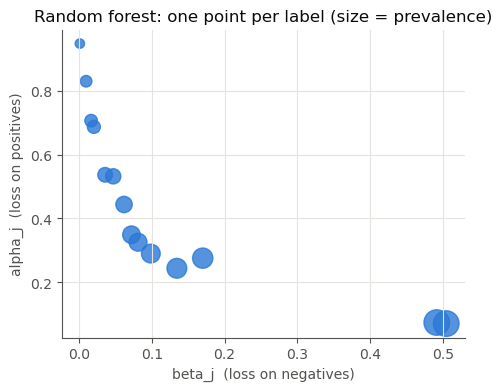

In [5]:
sm = scores["Random forest"]
ce = sm.conditional_errors()
mix = ce.prevalence * ce.alpha + (1 - ce.prevalence) * ce.beta
print("max |BS_j - mixture| :", np.abs(((sm.Y - sm.P) ** 2).mean(axis=0) - mix).max())

fig, ax = plt.subplots(figsize=(5.2, 4))
ax.scatter(ce.beta, ce.alpha, s=40 + 400 * ce.prevalence, color=BLUE, alpha=.8)
ax.set_xlabel("beta_j  (loss on negatives)")
ax.set_ylabel("alpha_j  (loss on positives)")
ax.set_title("Random forest: one point per label (size = prevalence)")
plt.show()

Rare labels (small points) have a high `alpha`: their few positives get low scores. Their Brier
score still looks small because the mixture is dominated by the negatives. `alpha_j` and
`beta_j` do not change if the label's prevalence does, so they compare labels and datasets that
the per-label Brier score cannot.

## The Murphy decomposition

`BS = UNC - RES + REL`: uncertainty of the label, resolution (how far the calibrated scores move
from the base rate) and reliability (the part of the loss that recalibration would remove).
Without bins the decomposition uses the level sets of the scores. Logistic regression scores are
continuous, so every score is distinct, each level set is one cell, and the decomposition just
restates the Brier score. `murphy` says so.

In [6]:
from aggmetrics.scores import murphy

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    m0 = murphy(scores["Logistic regression"])
print(caught[0].category.__name__ if caught else "no warning")
print("mean REL / mean BS:", round(float(np.mean(m0.rel) / np.mean(m0.brier)), 3))

DegenerateDecompositionWarning
mean REL / mean BS: 1.0


Two ways to get an informative split: equal-width bins (the decomposition is then exact for the
binned predictor, with the binning gap reported), or the isotonic recalibration of Dimitriadis,
Gneiting and Jordan (2021), which needs no bins.

In [7]:
rows = []
for name, sm in scores.items():
    b = murphy(sm, bins=10)
    i = murphy(sm, method="isotonic")
    rows.append({"model": name, "BS": b.brier.mean(),
                 "REL binned": b.rel.mean(), "RES binned": b.res.mean(),
                 "REL isotonic": i.rel.mean(), "RES isotonic": i.res.mean()})
pd.DataFrame(rows).set_index("model").round(4)

,BS,REL binned,RES binned,REL isotonic,RES isotonic
model,,,,,
Logistic regression,0.1494,0.0051,0.0193,0.0064,0.0208
Random forest,0.1385,0.0027,0.0278,0.0039,0.0296
kNN (k=10),0.1444,0.0046,0.0238,0.0050,0.0245


Averaged over the 14 labels, the random forest has the smallest reliability term and the largest
resolution under both estimators, and the logistic regression the opposite. The two estimators
agree on the order of the models; their values differ because bins and isotonic steps cut the
scores in different places. The isotonic reliability is a difference of Brier scores, so it is
not the squared distance between the scores and the recalibrated ones.

The same split per label shows where the reliability loss sits.

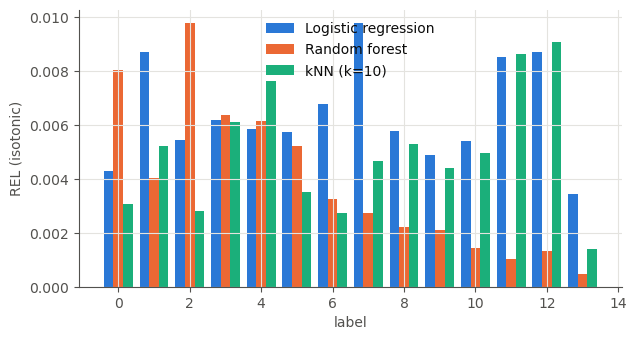

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.6))
width = .27
for k, (name, sm) in enumerate(scores.items()):
    rel = murphy(sm, method="isotonic").rel
    ax.bar(np.arange(Y.shape[1]) + (k - 1) * width, rel, width, label=name,
           color=[BLUE, ORANGE, AQUA][k])
ax.set_xlabel("label")
ax.set_ylabel("REL (isotonic)")
ax.legend(frameon=False)
plt.show()

## What to take away

- Report Brier once; the averaging convention does not matter for it.
- Report `alpha` and `beta` to see whether the loss falls on the positives or the negatives.
- Use `bins=` or `method="isotonic"` for the Murphy split; without them it restates the Brier
  score whenever the scores are distinct, as with logistic regression here.